# 06 Statewide numbers

Scale the pilot results to every tract.

**Inputs**
- `data/processed/6950_lots_pilot_full.csv` (lots_pilot.csv + tree loss, from notebook 05)
- `data/processed/acs_tract.csv (single_family_detached)`
- `data/raw/6950/ruca_2020_tract.csv`

**Output**
- `data/processed/lots_tract.csv  (GEOID, lots_total, lots_fit, lots_fit_keep_trees, tree_loss_m2, + lots_fit_low, lots_fit_high, stratum)`
- `data/processed/fit_curves.csv  (stratum, footprint_sqft, share_fit, share_fit_keep_trees, share_fit_low, share_fit_high)`
- `docs/figures/06_lots_fit_map.png`

Run `python musa6950/get_data.py` first. Use the geoai env.

In [1]:
import sys
import json
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
from common import RAW, OUT
R6 = RAW / "6950"
FIG = ROOT / "musa6950" / "docs" / "figures"

ruca = pd.read_csv(R6 / "ruca_2020_tract.csv", dtype={"TractFIPS20": str}, encoding="latin-1")
ruca = ruca[ruca.TractFIPS20.str[:2] == "42"].rename(columns={"TractFIPS20": "GEOID"})
ruca["group"] = pd.cut(pd.to_numeric(ruca.PrimaryRUCA, errors="coerce"), [0, 1, 3, 10],
                       labels=["urban", "suburban", "rural"]).astype(str)
acs = pd.read_csv(OUT / "acs_tract.csv", dtype={"GEOID": str})
acs = acs[acs.acs_year == 2024][["GEOID", "single_family_detached"]]
lots = pd.read_csv(OUT / "6950_lots_pilot_full.csv", dtype={"GEOID": str, "county": str})
lots = lots.merge(ruca[["GEOID", "group"]], on="GEOID", how="left")
print(len(lots), "pilot lots")
print(lots.groupby(["county_name", "group"]).size().unstack(fill_value=0))

83934 pilot lots
group         rural  suburban  urban
county_name                         
Cumberland     3527      9826  44311
Philadelphia      0         0  26270


## Fit rate by group

- urban (RUCA 1) / suburban (RUCA 2-3) / rural (RUCA 4-10)
- Urban = Philadelphia + Cumberland urban tracts. Suburban and rural = Cumberland only (Philadelphia is all RUCA 1)
- Tree loss per fitting lot = mean over lots that fit of the tree area cut (0 when the spot fits without cutting)
- Bootstrap 1,000 times for a range. Resample whole tracts, not single lots, since lots next to each other are alike

In [2]:
GROUPS = ["urban", "suburban", "rural"]


def rates(d):
    f = d.fits.astype(bool)
    return f.mean(), d.fits_keep_trees.astype(bool).mean(), (d.tree_loss_m2 * f).sum() / max(f.sum(), 1)


rows = []
rng = np.random.default_rng(42)
boot = {}
for g in GROUPS:
    d = lots[lots.group == g]
    fr, kr, loss = rates(d)
    per = d.assign(f=d.fits.astype(int), k=d.fits_keep_trees.astype(int)).groupby("GEOID")[["f", "k"]].agg(["sum", "size"])
    n, nf, nk = per[("f", "size")].values, per[("f", "sum")].values, per[("k", "sum")].values
    keys = per.index
    bs = []
    for _ in range(1000):
        pick = rng.integers(0, len(keys), len(keys))
        bs.append((nf[pick].sum() / n[pick].sum(), nk[pick].sum() / n[pick].sum()))
    bs = np.array(bs)
    boot[g] = bs
    rows.append({"group": g, "lots": len(d), "tracts": len(keys), "fit_rate": fr,
                 "fit_low": np.percentile(bs[:, 0], 2.5), "fit_high": np.percentile(bs[:, 0], 97.5),
                 "keep_trees_rate": kr, "keep_low": np.percentile(bs[:, 1], 2.5), "keep_high": np.percentile(bs[:, 1], 97.5),
                 "tree_loss_per_fit_m2": loss})
R = pd.DataFrame(rows).set_index("group")
for g in GROUPS:   # a group with no pilot lots borrows the next group's rates (none expected: Cumberland has all three)
    if R.loc[g, "lots"] == 0:
        alt = "suburban" if g != "suburban" else "urban"
        print(f"no pilot lots in {g}: using {alt} rates")
        R.loc[g, R.columns.drop(["lots", "tracts"])] = R.loc[alt, R.columns.drop(["lots", "tracts"])]
print(R.round(3).to_string())
print("\nBy county (for reference):")
print(lots.groupby(["county_name", "group"]).agg(lots=("lot_id", "size"), fit=("fits", "mean"),
                                                 keep=("fits_keep_trees", "mean")).round(3).to_string())

           lots  tracts  fit_rate  fit_low  fit_high  keep_trees_rate  keep_low  keep_high  tree_loss_per_fit_m2
group                                                                                                           
urban     70581     342     0.719    0.671     0.764            0.494     0.432      0.551                10.325
suburban   9826      11     0.966    0.934     0.990            0.873     0.815      0.931                 3.198
rural      3527       4     0.800    0.518     0.928            0.719     0.376      0.870                 2.839

By county (for reference):
                        lots    fit   keep
county_name  group                        
Cumberland   rural      3527  0.800  0.719
             suburban   9826  0.966  0.873
             urban     44311  0.857  0.654
Philadelphia urban     26270  0.487  0.223


## Apply to every tract

- lots_total = single-family detached homes (ACS 2020-24, B25024)
- lots_fit = lots_total x fit rate for the tract's group
- lots_fit_keep_trees = lots_total x keep-trees rate
- tree_loss_m2 = lots_fit x tree loss per fitting lot for the group
- lots_fit_low / lots_fit_high = 95% bootstrap range of the fit rate
- The same group rate is used in the pilot counties too, so every tract is made the same way. The lot-level map has the real per-lot answers

In [3]:
tracts = gpd.read_file(OUT / "tracts_2020.gpkg")
t = tracts[["GEOID"]].merge(acs, on="GEOID", how="left").merge(ruca[["GEOID", "group"]], on="GEOID", how="left")
t["stratum"] = t.group
print("tracts:", len(t), "| no ACS value:", t.single_family_detached.isna().sum(), "| no RUCA group:", (~t.group.isin(GROUPS)).sum())
print(t[~t.group.isin(GROUPS)])
t["lots_total"] = t.single_family_detached.fillna(0).round().astype(int)
g = t.group.where(t.group.isin(GROUPS))
t["lots_fit"] = (t.lots_total * g.map(R.fit_rate)).round()
t["lots_fit_keep_trees"] = (t.lots_total * g.map(R.keep_trees_rate)).round()
t["tree_loss_m2"] = (t.lots_fit * g.map(R.tree_loss_per_fit_m2)).round()
t["lots_fit_low"] = (t.lots_total * g.map(R.fit_low)).round()
t["lots_fit_high"] = (t.lots_total * g.map(R.fit_high)).round()
cols = ["lots_fit", "lots_fit_keep_trees", "tree_loss_m2", "lots_fit_low", "lots_fit_high"]
t[cols] = t[cols].fillna(0).astype(int)
lots_tract = t[["GEOID", "lots_total", "lots_fit", "lots_fit_keep_trees", "tree_loss_m2", "lots_fit_low", "lots_fit_high", "stratum"]]

tot = lots_tract.drop(columns=["GEOID", "stratum"]).sum()
tot_by = t.groupby("group")[["lots_total", "lots_fit", "lots_fit_keep_trees", "tree_loss_m2", "lots_fit_low", "lots_fit_high"]].sum()
print(tot_by.to_string())
print("\nStatewide:")
print(tot.to_string())
print(f"\nTree canopy lost if every fitting lot built one: {tot.tree_loss_m2 / 1e6:.2f} km2 ({tot.tree_loss_m2 / 4046.86:,.0f} acres)")

tracts: 3445 | no ACS value: 0 | no RUCA group: 0
Empty DataFrame
Columns: [GEOID, single_family_detached, group, stratum]
Index: []
          lots_total  lots_fit  lots_fit_keep_trees  tree_loss_m2  lots_fit_low  lots_fit_high
group                                                                                         
rural         783142    626160               563105       1777454        405305         726515
suburban      646067    623836               564335       1995117        603107         639367
urban        1858258   1336641               917162      13800605       1246978        1419250

Statewide:
lots_total              3287467
lots_fit                2586637
lots_fit_keep_trees     2044602
tree_loss_m2           17573176
lots_fit_low            2255390
lots_fit_high           2785132

Tree canopy lost if every fitting lot built one: 17.57 km2 (4,342 acres)


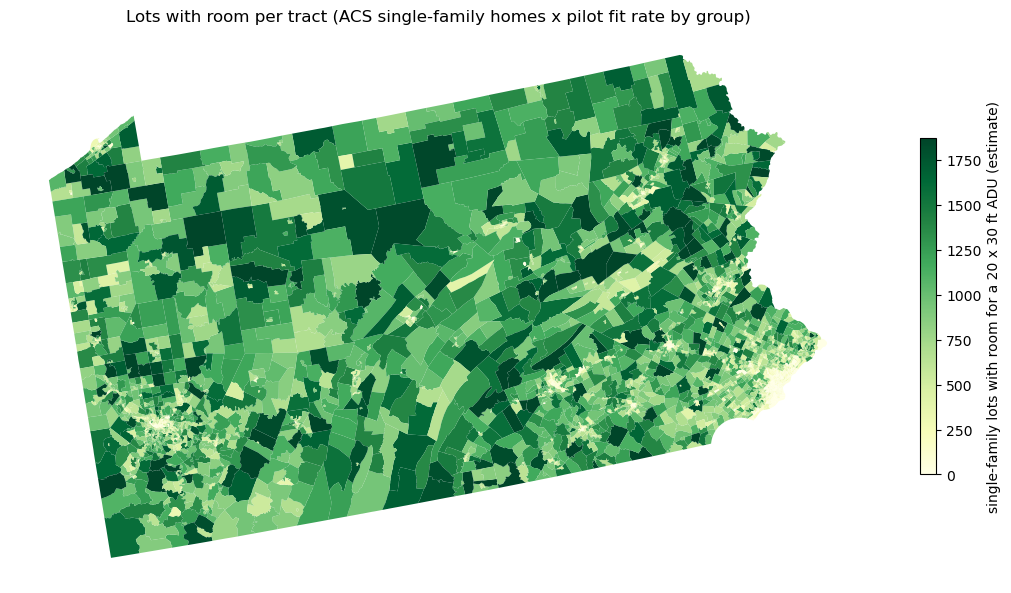

In [4]:
m = tracts.merge(lots_tract, on="GEOID").to_crs(5070)
m["share"] = m.lots_fit / m.lots_total.where(m.lots_total > 0)
fig, ax = plt.subplots(figsize=(11, 6))
m.plot(column="lots_fit", ax=ax, cmap="YlGn", scheme=None, legend=True, linewidth=0,
       legend_kwds={"label": "single-family lots with room for a 20 x 30 ft ADU (estimate)", "shrink": 0.6},
       vmax=np.percentile(m.lots_fit, 98))
ax.set_axis_off()
ax.set_title("Lots with room per tract (ACS single-family homes x pilot fit rate by group)")
plt.tight_layout()
plt.savefig(FIG / "06_lots_fit_map.png", dpi=110)
plt.show()

## Fit curves by footprint size

- For the tool's size slider: share of pilot single-family lots where a footprint of each size fits
- Ladder 100 to 2,000 sq ft in steps of 50 (from `max_fit_sqft` in notebook 05)
- Range = same tract bootstrap as above (1,000 times, seed 42)
- Check: at 600 sq ft the curve should be close to the group fit rate. It is not exactly the same because the ladder also tries a square and a 1:2 shape, and rounds pixel sizes up


          curve_600  group_rate  curve_600_keep  group_keep_rate
urban        0.7052      0.7193          0.4788           0.4936
suburban     0.9645      0.9656          0.8687           0.8735
rural        0.7910      0.7995          0.7091           0.7190


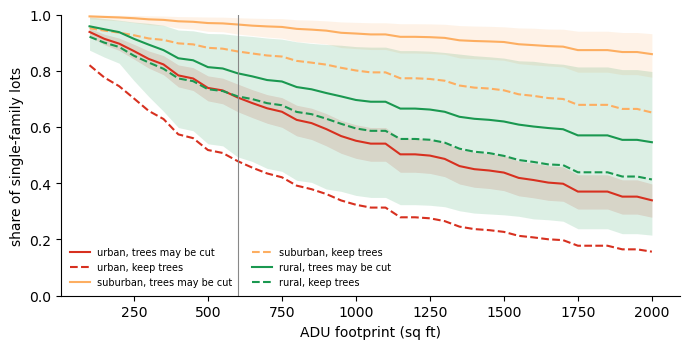

In [5]:
LAD = np.arange(100, 2001, 50)
rng_c = np.random.default_rng(42)
curves = []
for g in GROUPS:
    d = lots[lots.group == g]
    F = pd.DataFrame((d.max_fit_sqft.values[:, None] >= LAD).astype(int), index=d.GEOID.values)
    K = pd.DataFrame((d.max_fit_keep_trees_sqft.values[:, None] >= LAD).astype(int), index=d.GEOID.values)
    fs, ks, n = F.groupby(level=0).sum().values, K.groupby(level=0).sum().values, F.groupby(level=0).size().values
    bs = []
    for _ in range(1000):
        pick = rng_c.integers(0, len(n), len(n))
        bs.append(fs[pick].sum(0) / n[pick].sum())
    bs = np.array(bs)
    curves.append(pd.DataFrame({"stratum": g, "footprint_sqft": LAD, "share_fit": fs.sum(0) / n.sum(),
                                "share_fit_keep_trees": ks.sum(0) / n.sum(),
                                "share_fit_low": np.percentile(bs, 2.5, axis=0), "share_fit_high": np.percentile(bs, 97.5, axis=0)}))
fit_curves = pd.concat(curves, ignore_index=True)
assert (fit_curves.groupby("stratum").share_fit.apply(lambda s: s.is_monotonic_decreasing)).all()
c600 = fit_curves[fit_curves.footprint_sqft == 600].set_index("stratum")
curve_check = pd.DataFrame({"curve_600": c600.share_fit, "group_rate": R.fit_rate,
                            "curve_600_keep": c600.share_fit_keep_trees, "group_keep_rate": R.keep_trees_rate}).loc[GROUPS]
print(curve_check.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 3.6))
for g, col in zip(GROUPS, ["#d7301f", "#fdae61", "#1a9850"]):
    c = fit_curves[fit_curves.stratum == g]
    ax.fill_between(c.footprint_sqft, c.share_fit_low, c.share_fit_high, color=col, alpha=0.15, lw=0)
    ax.plot(c.footprint_sqft, c.share_fit, color=col, label=f"{g}, trees may be cut")
    ax.plot(c.footprint_sqft, c.share_fit_keep_trees, color=col, ls="--", label=f"{g}, keep trees")
ax.axvline(600, color="#888", lw=0.8)
ax.set_xlabel("ADU footprint (sq ft)"); ax.set_ylabel("share of single-family lots"); ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=7, ncol=2)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "06_fit_curves.png", dpi=110)
plt.show()


## Save

- Then run python app/build_data.py

In [6]:
lots_tract.to_csv(OUT / "lots_tract.csv", index=False)
fit_curves.round(4).to_csv(OUT / "fit_curves.csv", index=False)
json.dump({"rates": R.round(4).reset_index().to_dict("records"), "statewide": tot.astype(int).to_dict(),
           "by_group": tot_by.astype(int).reset_index().to_dict("records"), "n_tracts": int(len(lots_tract)),
           "fit_curve_check_600": curve_check.round(4).reset_index(names="stratum").to_dict("records")},
          open(OUT / "6950_metrics_statewide.json", "w"), indent=1)
print(len(lots_tract), "tracts saved")
lots_tract.head()

3445 tracts saved


,GEOID,lots_total,lots_fit,lots_fit_keep_trees,tree_loss_m2,lots_fit_low,lots_fit_high,stratum
0,42013100400,652,469,322,4842,438,498,urban
1,42013100700,775,557,383,5751,520,592,urban
2,42011000100,155,111,77,1146,104,118,urban
3,42011011702,1660,1603,1450,5127,1550,1643,suburban
4,42011000400,247,178,122,1838,166,189,urban
